## **Federated Learning Across Hospitals: A Comparative Study of Aggregation Methods Under Real Domain Shift Using CNNs on Multi-Hospital Histopathology Data**



# Group Information
Name: Sayka Ferdous

ID: 2023-3-60-110

Name: Asrafun Nahar Raisa

ID: 2023-3-60-228

Name: Khaleda Sultana Jamie

ID: 2023-3-60-397

Name: Tahira Tasnim

ID: 2023-3-60-267

### Part A: Dataset information


| Item | Details |
|---|---|
| **Name** | Camelyon17-WILDS (patch-based version, v1.0) |
| **Source link** | https://wilds.stanford.edu/datasets/#camelyon17 |
| **Original source** | CAMELYON17 Challenge (Bandi et al., 2018); WILDS benchmark (Koh et al., ICML 2021) |
| **Licence** | CC0 (public domain) |
| **Year** | 2018 (CAMELYON17), 2021 (WILDS patch version) |
| **Task type** | Binary classification: does the central 32×32 region of the patch contain tumor tissue? |
| **Number of classes** | 2 (0 = no tumor, 1 = tumor) |
| **Total images** | 455,954 patches |
| **Per-class counts** | No tumor: 227,977; Tumor: 227,977 (perfectly balanced) |
| **Hospitals (centers)** | 5 hospitals: 0 = 59,436; 1 = 34,904; 2 = 85,054; 3 = 129,838; 4 = 146,722 images |
| **Image size** | 96 × 96 pixels |
| **Channels** | **3 (RGB)**  |
| **File format** | **PNG** |



**Why this dataset matters:**
Camelyon17-WILDS contains histopathology images of lymph node tissue used to detect cancer metastases. Hospitals differ in scanners, staining and procedures, so a model trained on some hospitals often performs worse on a new one. This makes the dataset a realistic test of whether medical AI models generalize beyond the hospitals they were trained on, which matters for safe real-world use.

### Part B: Exploratory data analysis (EDA)

**Class imbalance:** None. Both classes have 227,977 images, and every hospital is exactly 50/50 tumor and no-tumor, so class weights are not needed for class imbalance.

**Hospital imbalance:** Hospital 4 has 146,722 images and hospital 1 has 34,904 (about 4.2 times fewer). Training uses hospitals 0, 3 and 4, validation uses hospital 1, and testing uses hospital 2, which is unseen during training.

**Federated setup:** The three WILDS training hospitals (0, 3, 4) act as federated clients. Hospital 1 is used only for validation and model selection. Hospital 2 is never seen during training and is the held-out test hospital, which measures how well the global model generalizes to a new hospital. Per-hospital results will be reported for clients 0, 3 and 4 (using the in-distribution validation split) and for hospitals 1 and 2.

**Noise and artifacts:** Some patches contain large black regions (padding at the slide edge) or mostly empty white background with only a thin strip of tissue. These patches carry little useful information.

**Stain and color variation:** Colors differ across hospitals. Some patches are dark reddish-purple (for example hospital 3), others pale lavender (for example hospital 4). This is the domain shift, and it can reduce accuracy on the unseen test hospital.

**Class similarity:** Tumor and no-tumor patches look alike at first glance, since both are dense with purple nuclei. Tumor patches tend to show larger, more irregular nuclei, so fine detail matters and the model must not rely on color alone.

**Planned preprocessing and augmentation:**
- Normalize pixel values (ImageNet mean and std for pretrained models), and resize to 224×224 where a pretrained model needs it.
- Random horizontal and vertical flips and 90-degree rotations, since tissue has no fixed orientation.
- Color jitter (brightness, contrast, saturation, hue) to reduce sensitivity to stain differences between hospitals.
- Use a random subset of the training data for the 30 to 50 epoch experiments, due to Colab limits.

### Part C: Related work summary


| # | Paper (author, year) | Dataset used | Model(s) | Approach | Result (accuracy / F1 / AUC) | Reference link |
|---|---|---|---|---|---|---|
| 1 | Koh et al., 2021, "WILDS: A Benchmark of in-the-Wild Distribution Shifts" | Camelyon17-WILDS | DenseNet-121 (trained from scratch) | Standard ERM training on hospitals 0, 3, 4; validation on hospital 1; test on hospital 2 | Test accuracy on unseen hospital 2: 70.3 ± 6.4% (validation 84.9 ± 3.1%) | https://arxiv.org/abs/2012.07421 |
| 2 | Shi et al., 2021, "Gradient Matching for Domain Generalization" (Fish) | Camelyon17-WILDS | DenseNet-121 (pretrained with ERM, then fine-tuned) | Gradient matching across hospitals (domains) to learn features that generalize | Test accuracy on unseen hospital 2: 74.7 ± 7.1% | https://arxiv.org/abs/2104.09937 |
| 3 | Yao et al., 2022, "Improving Out-of-Distribution Robustness via Selective Augmentation" (LISA) | Camelyon17-WILDS | Same WILDS DenseNet-121 setup | Selective data augmentation (mixing samples across hospitals) | Test accuracy on unseen hospital 2: 77.1 ± 6.5% | https://arxiv.org/abs/2201.00299 |
| 4 | McMahan et al., 2017, "Communication-Efficient Learning of Deep Networks from Decentralized Data" (FedAvg) | MNIST (IID and non-IID split), CIFAR-10, Shakespeare, large-scale social media posts (not Camelyon17) | MLP (2NN), CNN, character LSTM, word LSTM | Federated Averaging: each client runs several local SGD epochs on its own data, then the server averages the weights (no raw data shared) | Needs 10-100x fewer communication rounds than FedSGD. MNIST CNN (99% target): up to 35x fewer rounds on IID data, 2.8-3.7x on non-IID data. CIFAR-10: 85% test accuracy in 2,000 rounds (standard SGD: 86% after 197,500 updates) | https://arxiv.org/abs/1602.05629 |
| 5 | Li et al., 2020, "Federated Optimization in Heterogeneous Networks" (FedProx) | Synthetic, MNIST, FEMNIST, Shakespeare, Sent140 (not Camelyon17) | Multinomial logistic regression (MNIST, FEMNIST, synthetic), LSTM (Shakespeare, Sent140) | FedProx: adds a proximal term to each client objective to keep local models close to the global model, and accepts partial work from slow clients, so it handles non-identical client data | More stable convergence than FedAvg; improves absolute test accuracy by 22% on average in highly heterogeneous settings (90% stragglers) | https://arxiv.org/abs/1812.06127 |


###Install wilds and download the data

In [ ]:
import os
if not os.path.exists("/content/data/camelyon17_v1.0/metadata.csv"):
    !rm -rf /content/data/camelyon17_v1.0
    !mkdir -p /content/data/camelyon17_v1.0
    !wget --no-check-certificate -O /content/data/camelyon17_v1.0/archive.tar.gz "https://worksheets.codalab.org/rest/bundles/0xe45e15f39fb54e9d9e919556af67aabe/contents/blob/"
    !tar -xzf /content/data/camelyon17_v1.0/archive.tar.gz -C /content/data/camelyon17_v1.0
    !rm /content/data/camelyon17_v1.0/archive.tar.gz
else:
    print("Data already downloaded, skipping.")

!pip install -q wilds
from wilds import get_dataset
dataset = get_dataset(dataset="camelyon17", download=False, root_dir="/content/data")
print("Loaded:", dataset)

Data already downloaded, skipping.
Loaded: <wilds.datasets.camelyon17_dataset.Camelyon17Dataset object at 0x7fe47b2c9310>


### Check the files and metadata

In [ ]:
import os, pandas as pd
print(os.listdir("/content/data"))

meta = pd.read_csv("/content/data/camelyon17_v1.0/metadata.csv", index_col=0)
print(meta.shape)
print(meta.columns.tolist())
print(meta["tumor"].value_counts())
print(meta["center"].value_counts())

['camelyon17_v1.0']
(455954, 8)
['patient', 'node', 'x_coord', 'y_coord', 'tumor', 'slide', 'center', 'split']
tumor
1    227977
0    227977
Name: count, dtype: int64
center
4    146722
3    129838
2     85054
0     59436
1     34904
Name: count, dtype: int64


### Image details and hospital/split check

In [ ]:
print(dataset.get_input(0).size, dataset.get_input(0).mode)
print(dataset._input_array[0])   # file name shows the format, e.g. .png
print(pd.crosstab(meta["center"], meta["split"]))
print(pd.crosstab(meta["center"], meta["tumor"]))
for s in ["train", "val", "test", "id_val"]:
    print(s, len(dataset.get_subset(s)))

(96, 96) RGB
patches/patient_004_node_4/patch_patient_004_node_4_x_3328_y_21792.png
split        0      1
center               
0        53425   6011
1        31430   3474
2        76493   8561
3       116959  12879
4       132052  14670
tumor       0      1
center              
0       29718  29718
1       17452  17452
2       42527  42527
3       64919  64919
4       73361  73361
train 302436
val 34904
test 85054
id_val 33560


### Bar charts

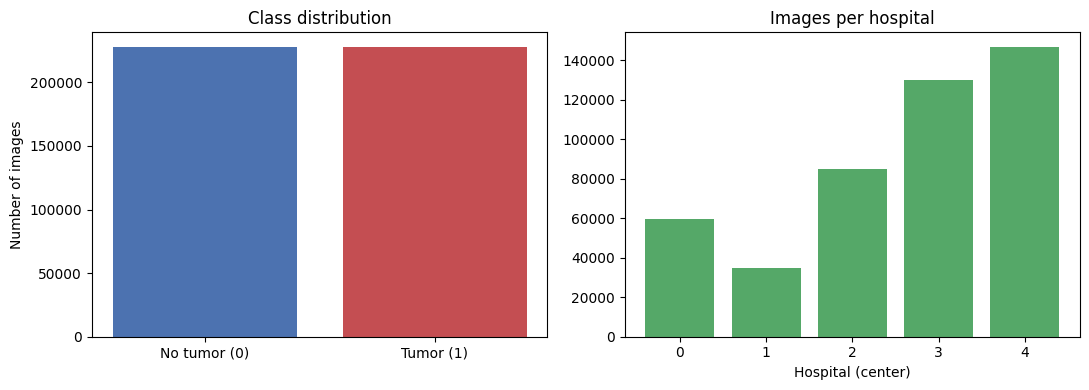

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = meta["tumor"].value_counts().sort_index()
ax[0].bar(["No tumor (0)", "Tumor (1)"], counts.values, color=["#4c72b0", "#c44e52"])
ax[0].set_title("Class distribution")
ax[0].set_ylabel("Number of images")

hosp = meta["center"].value_counts().sort_index()
ax[1].bar(hosp.index.astype(str), hosp.values, color="#55a868")
ax[1].set_title("Images per hospital")
ax[1].set_xlabel("Hospital (center)")

plt.tight_layout()
plt.show()

### Sample image grid

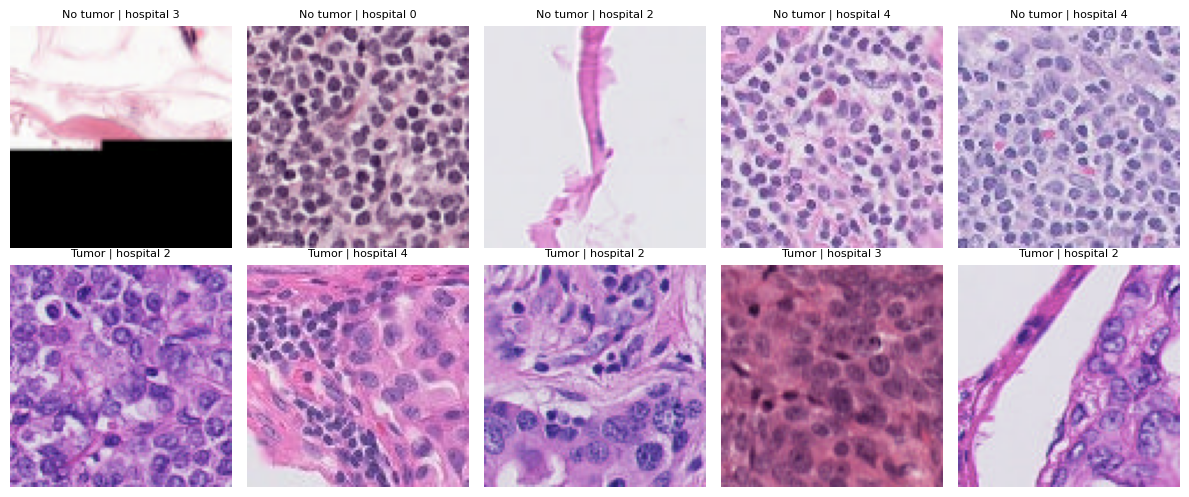

In [ ]:
import numpy as np

rng = np.random.RandomState(42)
y = meta["tumor"].values
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for row, cls in enumerate([0, 1]):
    idxs = rng.choice(np.where(y == cls)[0], 5, replace=False)
    for col, i in enumerate(idxs):
        axes[row, col].imshow(dataset.get_input(i))
        axes[row, col].axis("off")
        name = "Tumor" if cls == 1 else "No tumor"
        axes[row, col].set_title(f"{name} | hospital {meta['center'].iloc[i]}", fontsize=8)

plt.tight_layout()
plt.show()